# Credit-card fraud detection

Reproduce Ghalwash et al. (Scientific Reports 2025) — DBSCAN labels + RF/KNN/SVM + OR-vote — then try simpler, stronger models.

This notebook **displays saved results**. Heavy fitting already ran via `python -m src.eda` / `baseline` / `fe_eval` / `advanced` / `compare`. Run those first if a JSON file is missing.

1. Data and subsets
2. EDA
3. Paper baseline (with and without leakage)
4. Feature-engineering bake-off
5. XGBoost / LightGBM / MLP
6. Final comparison
7. 2013 data (skipped)


## 0. Setup

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import DATA_PATH, PLOTS_DIR, POSITIVE_LABEL, RANDOM_STATE, TABLES_DIR
from src.data import load_cleaned, load_named_subsets, subset_summary

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)


def show_img(path, takeaway=None):
    path = Path(path)
    if not path.exists():
        print("missing", path)
        return
    display(Image(filename=str(path)))
    if takeaway:
        display(Markdown("**Takeaway.** " + takeaway))


def load_json(name):
    path = TABLES_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"{path} missing. Run the matching `python -m src.*` command first.")
    return json.loads(path.read_text(encoding="utf-8"))


print("root", ROOT)
print("csv exists", DATA_PATH.exists(), "| seed", RANDOM_STATE, "| fraud label", POSITIVE_LABEL)


C:\Users\Charan\AppData\Local\Temp\ipykernel_21092\515830565.py:5: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


root d:\Acads\Sem 5\ML Lab\Project\Credit-card-fraud-detection-using-DBSCAN
csv exists True | seed 42 | fraud label 1


## 1. Data and subsets

Paper uses three 1% fraud slices: D1=40,400, D2=80,800, D3=121,200. The Kaggle 2023 file is actually **50/50**. We build the 1% rate by nested sampling (D1 ⊂ D2 ⊂ D3), seed 42.


In [2]:
raw = load_cleaned()
print("raw shape", raw.shape)
print(raw["Class"].value_counts())
print("nulls", int(raw.isnull().sum().sum()), "dups", int(raw.duplicated().sum()))

subsets = load_named_subsets(raw)
rows = []
for name, frame in subsets.items():
    info = subset_summary(frame)
    info["name"] = name
    rows.append(info)
display(pd.DataFrame(rows).set_index("name"))

ids = {n: set(subsets[n]["id"]) for n in ("D1", "D2", "D3")}
print("D1 inside D2", ids["D1"].issubset(ids["D2"]))
print("D2 inside D3", ids["D2"].issubset(ids["D3"]))


raw shape (568630, 31)
Class
0    284315
1    284315
Name: count, dtype: int64
nulls 0 dups 0


,n,n_nonfraud,n_fraud,fraud_rate
name,,,,
D1,40400,40000,400,0.009901
D2,80800,80000,800,0.009901
D3,121200,120000,1200,0.009901


D1 inside D2 True
D2 inside D3 True


**Takeaway.** `Class == 1` is fraud. Drop-na/drop-duplicates does nothing here. The paper's "imbalanced European 2023 data" is a **constructed** 1% sample of a balanced file.


## 2. EDA

In [3]:
summary = load_json("eda_summary.json")
print("Amount mean", round(summary["amount_mean"], 1), "Amount AUC", round(summary["amount_auc"], 3))
print("top features", [(r["feature"], round(r["auc"], 3)) for r in summary["top_auc"][:5]])
print("logreg probe", summary["probe"]["logreg"])
print("DBSCAN", summary["dbscan"])


Amount mean 12040.7 Amount AUC 0.515
top features [('V14', 0.977), ('V12', 0.952), ('V4', 0.95), ('V11', 0.947), ('V10', 0.932)]
logreg probe {'recall': 0.9875, 'precision': 0.34051724137931033, 'f1': 0.5064102564102564, 'pr_auc': 0.9499844765445211, 'roc_auc': 0.99848125, 'mcc': 0.5741297695737452}
DBSCAN {'n_clusters': 224, 'noise_frac': 0.3798886138613861, 'fraud_n': 320, 'fraud_in_noise': 249, 'fraud_in_cluster': 71, 'fraud_noise_rate': 0.778125, 'noise_that_is_fraud': 0.020280175924417658}


### Class counts

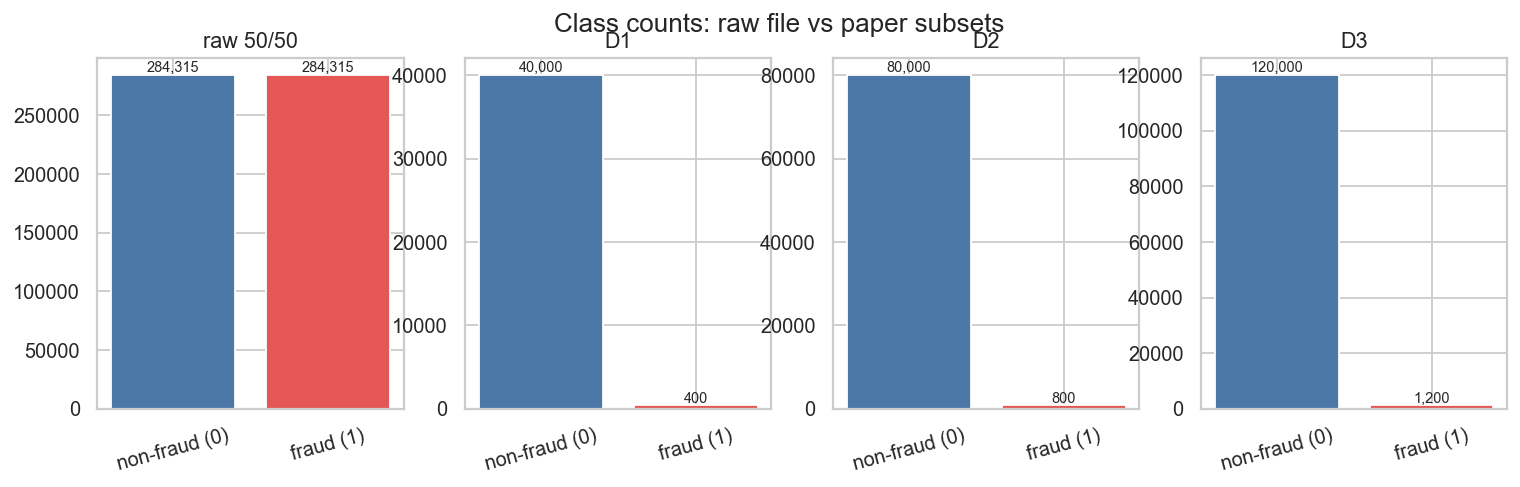

**Takeaway.** Raw file is 50/50. D1–D3 are 1% only because we undersampled.

In [4]:
show_img(PLOTS_DIR / "eda" / "01_class_counts.png", "Raw file is 50/50. D1–D3 are 1% only because we undersampled.")


### Amount vs V-features

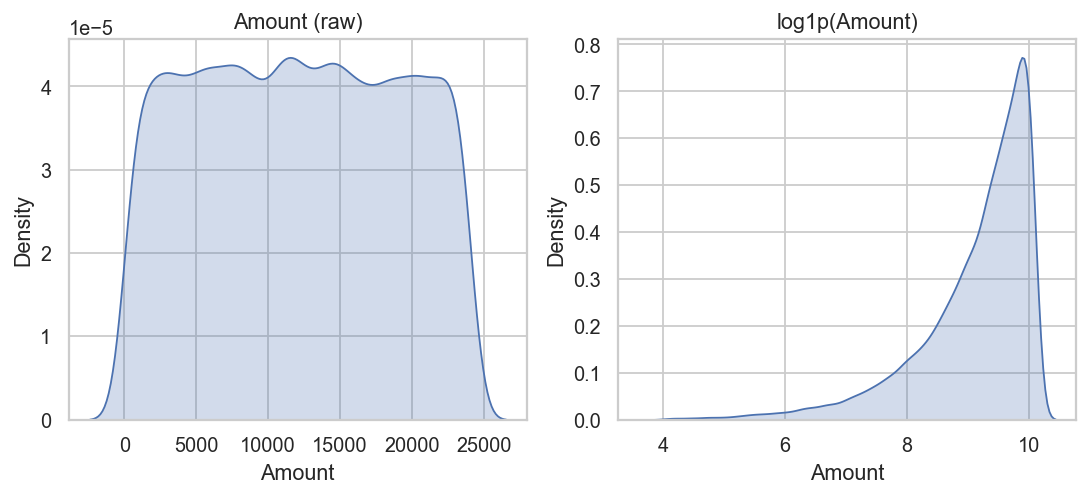

**Takeaway.** Amount is a different scale (needs StandardScaler). Skew is ~0, so skip log1p.

In [5]:
show_img(PLOTS_DIR / "eda" / "02_amount_dist.png", "Amount is a different scale (needs StandardScaler). Skew is ~0, so skip log1p.")


### Which columns separate fraud

,feature,auc,ks,mi
0,V14,0.977288,0.883575,0.041899
1,V12,0.951791,0.803000,0.036007
2,V4,0.950180,0.780075,0.024158
3,V11,0.947198,0.796975,0.033932
4,V10,0.931953,0.834525,0.037906
5,V3,0.931259,0.712450,0.025682
6,V9,0.881186,0.603525,0.019548
7,V2,0.870738,0.626725,0.016400


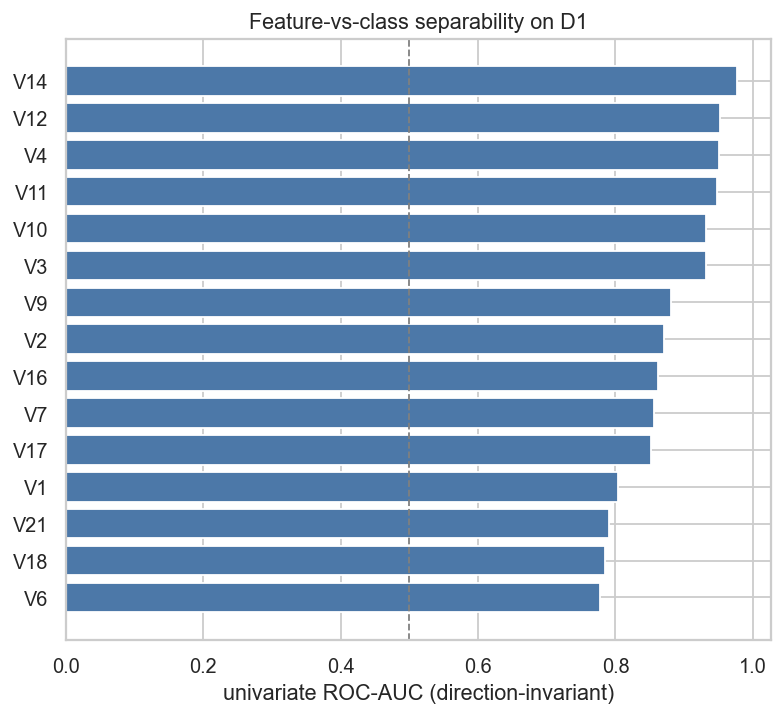

**Takeaway.** V14 is already almost a detector (AUC 0.977). Amount is useless (AUC 0.52).

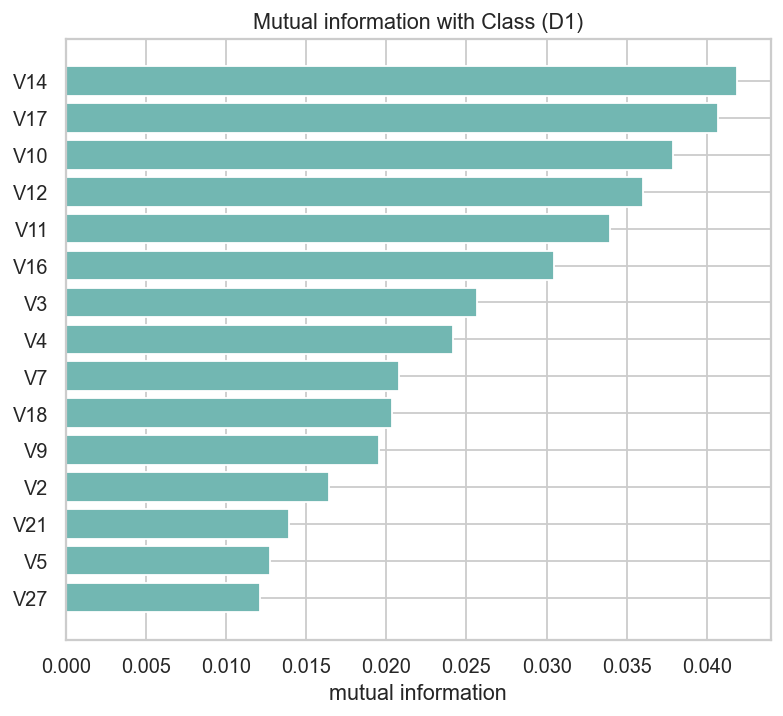

**Takeaway.** MI agrees on the same handful of V columns.

In [6]:
rank = pd.read_json(TABLES_DIR / "eda_univariate.json")
display(rank.head(8))
show_img(PLOTS_DIR / "eda" / "03_univariate_auc.png", "V14 is already almost a detector (AUC 0.977). Amount is useless (AUC 0.52).")
show_img(PLOTS_DIR / "eda" / "04_univariate_mi.png", "MI agrees on the same handful of V columns.")


### Top features by class

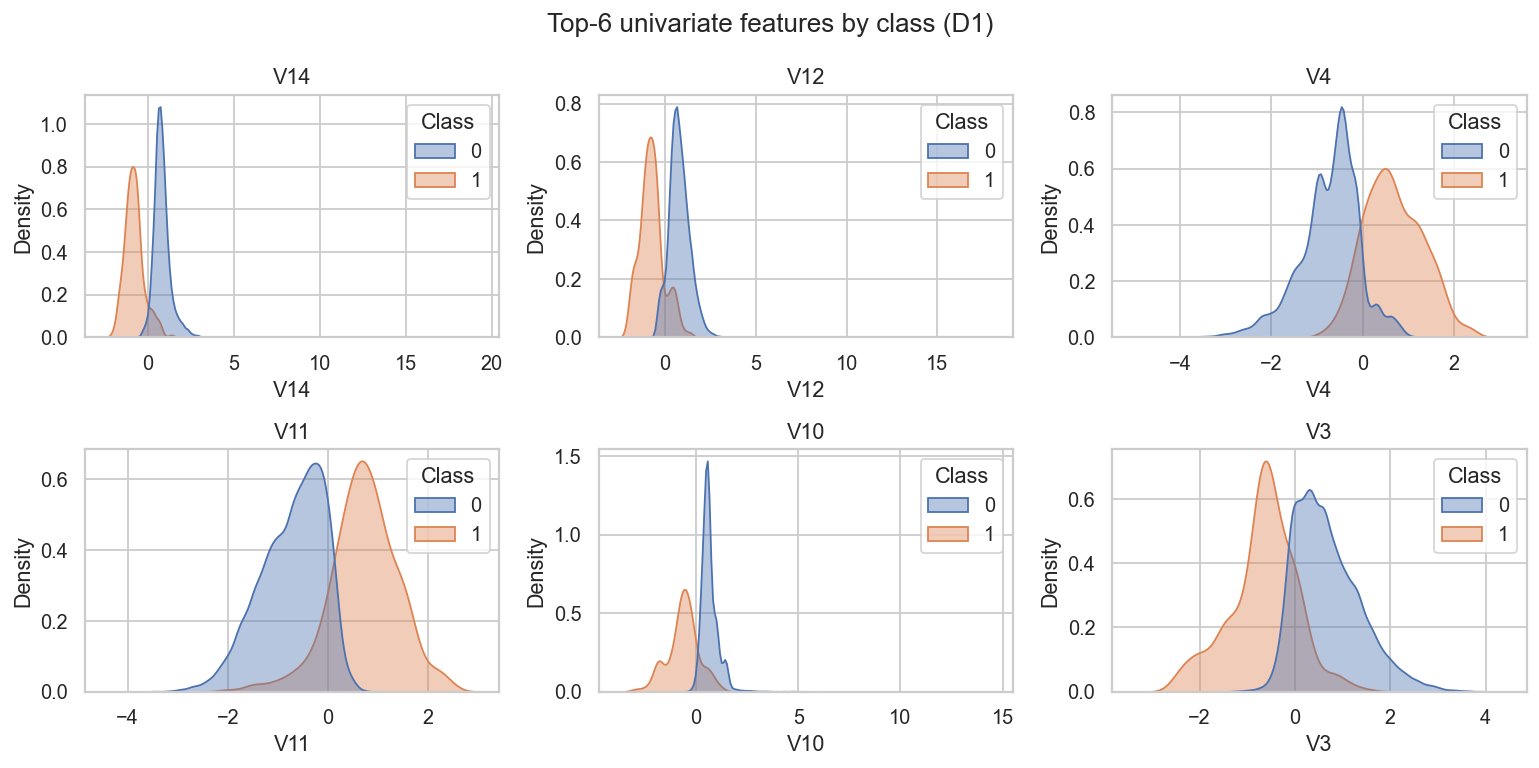

**Takeaway.** Red/blue densities barely overlap. A linear model can do well — this set may be too easy.

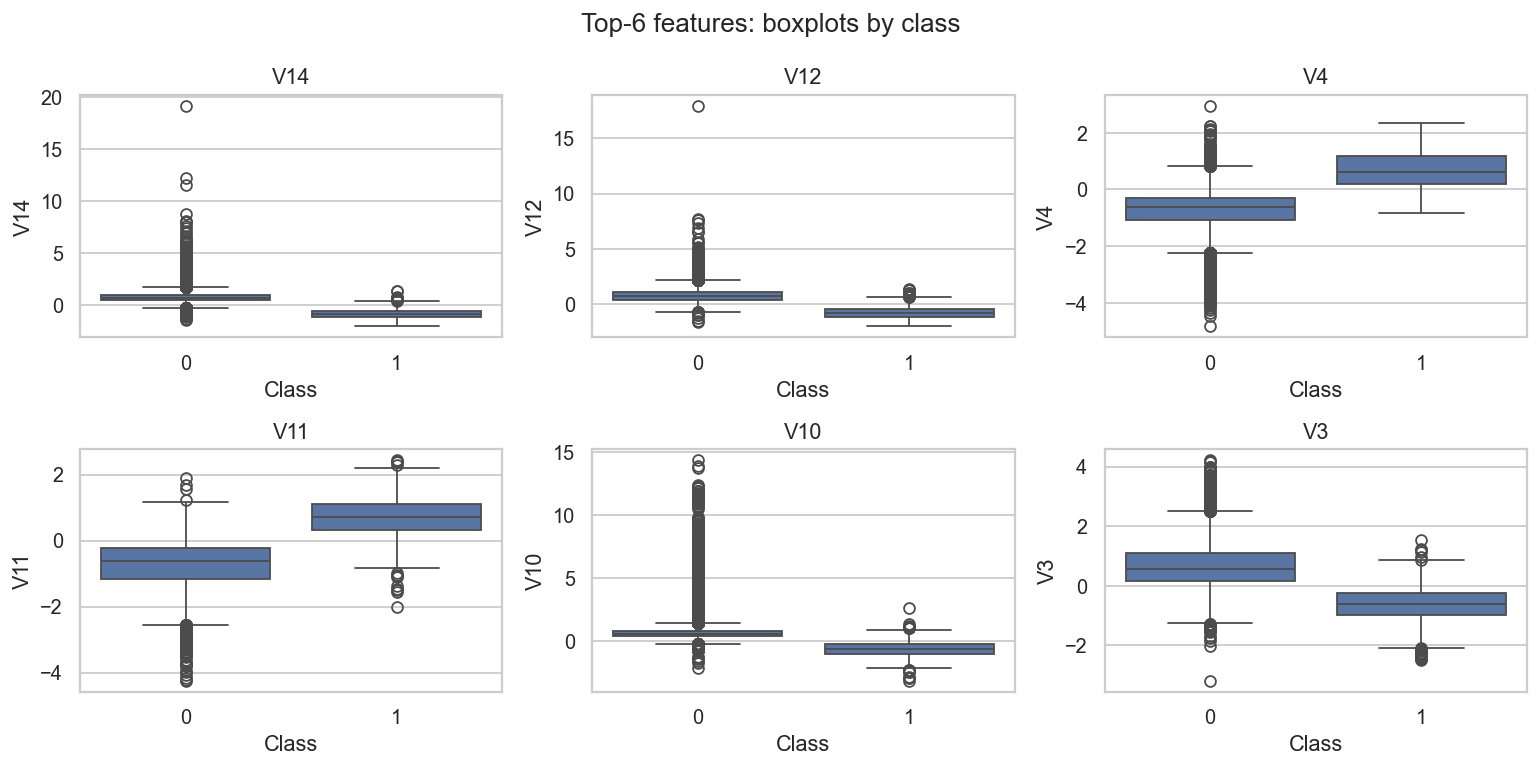

**Takeaway.** Same story in boxplots: location shift, not just a few outliers.

In [7]:
show_img(PLOTS_DIR / "eda" / "05_top_kde.png", "Red/blue densities barely overlap. A linear model can do well — this set may be too easy.")
show_img(PLOTS_DIR / "eda" / "06_top_box.png", "Same story in boxplots: location shift, not just a few outliers.")


### Correlation and a second PCA

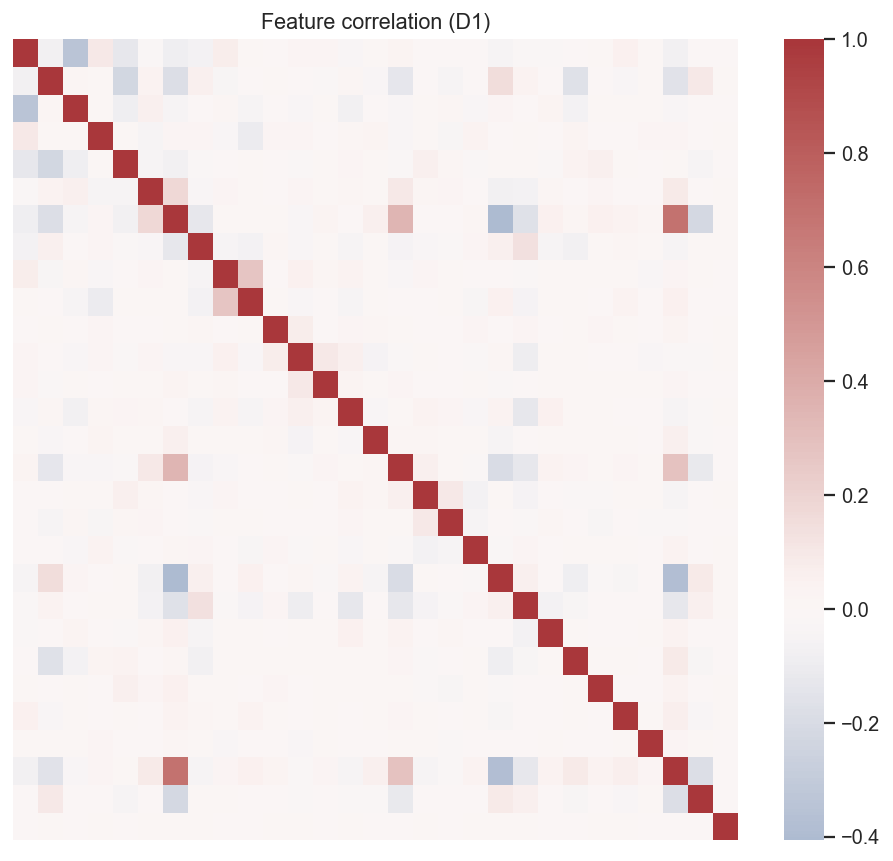

**Takeaway.** Some leftover correlation (max |r| ~0.70).

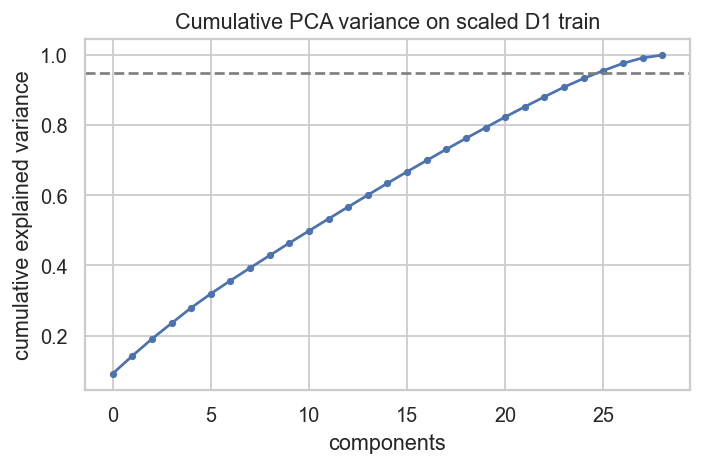

**Takeaway.** 95% variance still needs 26 of 29 components. Extra PCA is cosmetic; keep it only in the paper replica.

In [8]:
show_img(PLOTS_DIR / "eda" / "07_corr.png", "Some leftover correlation (max |r| ~0.70).")
show_img(PLOTS_DIR / "eda" / "14_pca_variance.png", f"95% variance still needs {summary['pca_n_for_95']} of 29 components. Extra PCA is cosmetic; keep it only in the paper replica.")


### Outliers

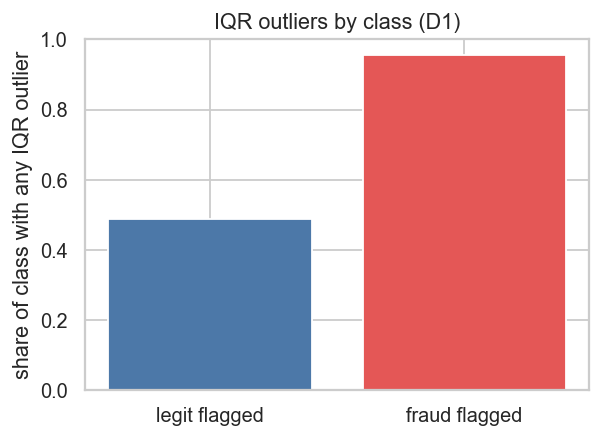

**Takeaway.** 95% of fraud vs 49% of legit trip an IQR flag. Anomaly scores are more natural than cluster IDs.

In [9]:
show_img(PLOTS_DIR / "eda" / "08_outliers.png", "95% of fraud vs 49% of legit trip an IQR flag. Anomaly scores are more natural than cluster IDs.")


### 2D views (8k subsample)

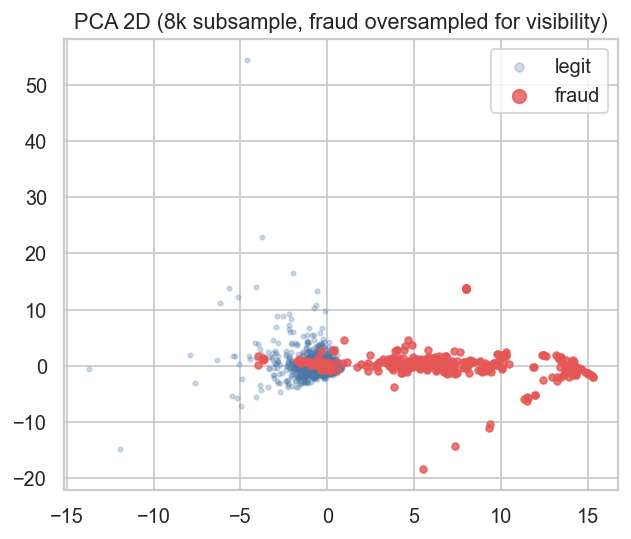

**Takeaway.** Even linear 2D already separates many fraud points.

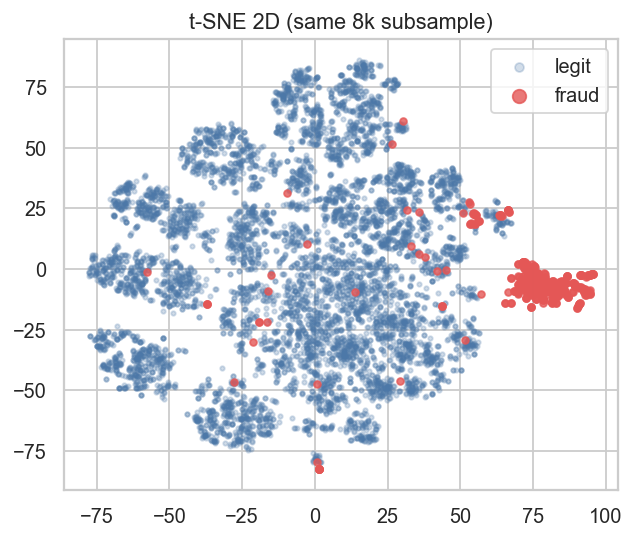

**Takeaway.** t-SNE also shows structure. Use as a picture, not as a feature.

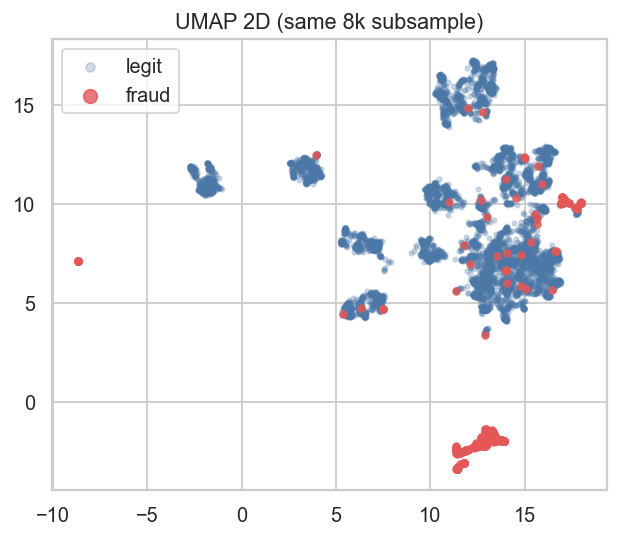

**Takeaway.** UMAP agrees. Compact groups justify trying KMeans distances later.

In [10]:
show_img(PLOTS_DIR / "eda" / "09_pca2.png", "Even linear 2D already separates many fraud points.")
show_img(PLOTS_DIR / "eda" / "10_tsne2.png", "t-SNE also shows structure. Use as a picture, not as a feature.")
show_img(PLOTS_DIR / "eda" / "11_umap2.png", "UMAP agrees. Compact groups justify trying KMeans distances later.")


### Is DBSCAN appropriate?

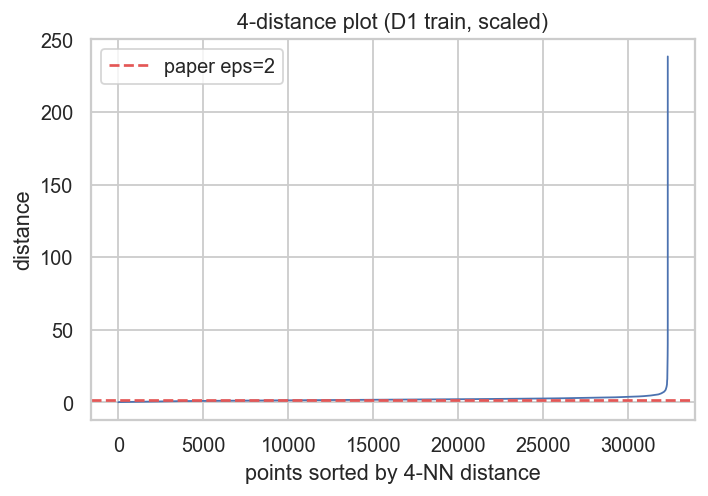

**Takeaway.** Paper eps=2 sits near the median 4-distance, not a sharp knee. About 46% of points are farther than 2.

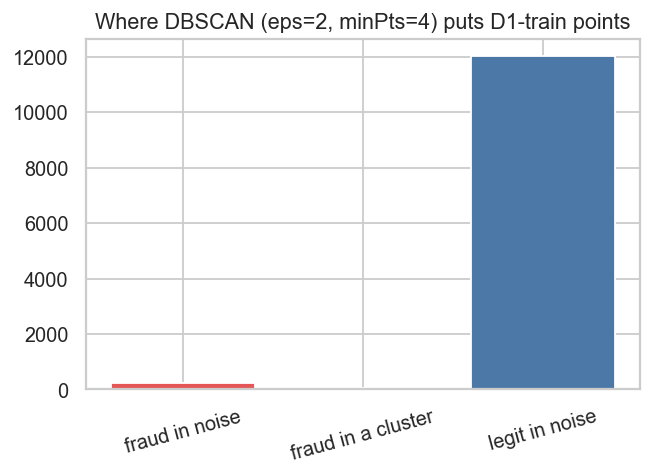

**Takeaway.** 78% of D1-train fraud is labelled noise. Noise is still ~98% legitimate. Cluster labels are a weak fraud signal.

In [11]:
show_img(PLOTS_DIR / "eda" / "12_kdistance.png", "Paper eps=2 sits near the median 4-distance, not a sharp knee. About 46% of points are farther than 2.")
show_img(PLOTS_DIR / "eda" / "13_dbscan_where.png", "78% of D1-train fraud is labelled noise. Noise is still ~98% legitimate. Cluster labels are a weak fraud signal.")


### Too easy? Shallow probe (leakage-safe D1)

In [12]:
display(pd.DataFrame(summary["probe"]).T)
display(Markdown(
    "**Takeaway.** Logistic PR-AUC is 0.95 and ROC-AUC is 0.998. Table 11's 0.995 recall is not surprising on this file, "
    "and it is not evidence the method works on messy real fraud. Skip autoencoders."
))


,recall,precision,f1,pr_auc,roc_auc,mcc
logreg,0.9875,0.340517,0.506410,0.949984,0.998481,0.574130
tree_d3,0.9625,0.162447,0.277978,0.460157,0.972924,0.384622


**Takeaway.** Logistic PR-AUC is 0.95 and ROC-AUC is 0.998. Table 11's 0.995 recall is not surprising on this file, and it is not evidence the method works on messy real fraud. Skip autoencoders.

### Findings → decisions

In [13]:
decisions = pd.read_json(TABLES_DIR / "eda_decisions.json")
display(decisions)


,finding,decision,reason
0,Raw file is 50/50; D1-D3 are 1% by construction,treat paper imbalance-handling claims as metho...,cannot claim real-world rarity from this file
1,Amount scale >> V features (mean 12041 vs |V| ...,standardise Amount; skip log1p (skew ~0) and t...,KNN/DBSCAN/SVM are distance-based
2,Max |feature corr| = 0.698; PCA-95 needs 26 co...,skip extra PCA in our methods (keep it only in...,V1-V28 are already PCA features; a second PCA ...
3,Top univariate AUC is V14=0.977; Amount AUC=0.515,use top-MI / top-AUC selection as one FE varia...,a few V columns carry most of the signal
4,IQR outlier share: fraud 0.95 vs legit 0.49,include IsolationForest and LOF scores as FE c...,"if fraud lives in tails, anomaly scores beat c..."
5,"DBSCAN eps=2 on D1 train: 224 clusters, noise=...",do not rely on DBSCAN labels as the main signa...,paper hyperparameters may not match the k-dist...
6,"Leakage-safe logreg PR-AUC=0.950, depth-3 tree...",trees/boosting as the fair FE workhorse; skip ...,a shallow probe is the honesty check the paper...
7,1% class rate after sampling,class weights / scale_pos_weight first; SMOTE ...,compare rebalancing to DBSCAN augmentation wit...
8,Near-linear separability probe PR-AUC=0.950,skip autoencoder reconstruction error,PLAN: skip AE if 2.10 already shows near-linea...
9,"Paper uses RF(n=3), KNN(k=3), RBF-SVM",replicate those as baseline only; Step 5 uses ...,n_estimators=3 is an unusually weak forest; bo...


## 3. Paper baseline

Same models as the paper: RF (`n_estimators=3`), KNN (`k=3`), SVM (RBF, `C=1`).

- **paper_style:** scale + PCA + DBSCAN on the **full** subset, then split (can leak).
- **leakage_safe:** split first; DBSCAN on train; test labels = nearest train point.

OR-vote (DVE) = fraud if **any** model says fraud. Majority = at least two. DBSCAN iterations tried: 1, 2, 3 on D1; **1** was closest to Table 11.


In [14]:
choice = load_json("dbscan_iteration_choice.json")
print("iteration search", choice)

base = pd.DataFrame(load_json("baseline_results.json"))
keep = [c for c in ["dataset", "mode", "augment", "model", "precision", "recall", "f1", "pr_auc", "fp", "fn", "seconds", "paper_recall", "recall_gap"] if c in base.columns]
display(base[keep].sort_values(["dataset", "mode", "augment", "model"]))


iteration search {'target_recall': 0.988, 'tried': [{'n_iterations': 1, 'recall': 0.9, 'f1': 0.9113924050632911, 'abs_gap': 0.08799999999999997}, {'n_iterations': 2, 'recall': 0.8625, 'f1': 0.8961038961038961, 'abs_gap': 0.12549999999999994}, {'n_iterations': 3, 'recall': 0.8875, 'f1': 0.9044585987261147, 'abs_gap': 0.10050000000000003}], 'chosen': 1}


,dataset,mode,augment,model,precision,recall,f1,pr_auc,fp,fn,seconds,paper_recall,recall_gap
16,D1,leakage_safe,dbscan_x1,KNN,0.970588,0.825000,0.891892,0.929948,2,14,1.181471,NaN,NaN
15,D1,leakage_safe,dbscan_x1,RandomForest,0.985075,0.825000,0.897959,0.860363,1,14,0.450887,NaN,NaN
17,D1,leakage_safe,dbscan_x1,SVM,0.984848,0.812500,0.890411,0.909354,1,15,1.714516,NaN,NaN
19,D1,leakage_safe,dbscan_x1,disjunctive,0.972973,0.900000,0.935065,0.925348,2,8,2.273220,0.988,-0.088000
18,D1,leakage_safe,dbscan_x1,majority,0.970588,0.825000,0.891892,0.980930,2,14,2.273220,NaN,NaN
11,D1,leakage_safe,none,KNN,0.970588,0.825000,0.891892,0.937269,2,14,1.036614,0.680,0.145000
10,D1,leakage_safe,none,RandomForest,0.956522,0.825000,0.885906,0.869646,3,14,0.459672,0.780,0.045000
12,D1,leakage_safe,none,SVM,0.970588,0.825000,0.891892,0.961918,2,14,3.581978,0.750,0.075000
14,D1,leakage_safe,none,disjunctive,0.958904,0.875000,0.915033,0.921476,3,10,0.342559,NaN,NaN
13,D1,leakage_safe,none,majority,0.970588,0.825000,0.891892,0.976063,2,14,0.342559,0.790,0.035000


### Versus paper Table 11 (DVE)

In [15]:
dve = base[(base["model"] == "disjunctive") & (base["augment"].astype(str).str.contains("dbscan"))]
display(dve[[c for c in ["dataset", "mode", "recall", "precision", "f1", "pr_auc", "paper_recall", "recall_gap", "fp", "fn"] if c in dve.columns]])

gap = dve["recall_gap"].abs().min() if "recall_gap" in dve.columns else None
paper_mean = dve.loc[dve["mode"] == "paper_style", "recall"].mean()
safe_mean = dve.loc[dve["mode"] == "leakage_safe", "recall"].mean()
display(Markdown(
    f"**Takeaway.** Closest |recall gap| vs Table 11 is {gap:.3f}. "
    f"Mean DVE recall paper-style={paper_mean:.3f}, leakage-safe={safe_mean:.3f}. "
    "We did **not** reproduce 0.988-0.995. Leakage does not explain the gap - both modes look similar."
))


,dataset,mode,recall,precision,f1,pr_auc,paper_recall,recall_gap,fp,fn
9,D1,paper_style,0.900000,0.923077,0.911392,0.912012,0.988,-0.088000,6,8
19,D1,leakage_safe,0.900000,0.972973,0.935065,0.925348,0.988,-0.088000,2,8
29,D2,paper_style,0.887500,0.928105,0.907348,0.884961,0.994,-0.106500,11,18
39,D2,leakage_safe,0.868750,0.932886,0.899676,0.877410,0.994,-0.125250,10,21
49,D3,paper_style,0.925000,0.944681,0.934737,0.935342,0.995,-0.070000,13,18
59,D3,leakage_safe,0.933333,0.906883,0.919918,0.919917,0.995,-0.061667,23,16


**Takeaway.** Closest |recall gap| vs Table 11 is 0.062. Mean DVE recall paper-style=0.904, leakage-safe=0.901. We did **not** reproduce 0.988-0.995. Leakage does not explain the gap - both modes look similar.

## 4. Feature engineering

Fair test: **same LightGBM**, leakage-safe, D1 first.

| EDA finding | Variant |
|---|---|
| Linear model already strong | skip autoencoder |
| Amount skew ~0 | skip log(Amount) |
| Extra PCA needs 26/29 components | no second PCA here |
| Fraud often looks like noise | IsolationForest, LOF |
| Some 2D blobs | KMeans id + distances |
| V14/V12/V4 dominate | top-8 AUC features |
| 1% rate is synthetic | SMOTE vs class weights |
| Paper idea | DBSCAN labels (train-only) |


In [16]:
fe = load_json("fe_results.json")
display(Markdown(f"**Winner by D1 PR-AUC:** `{fe['winner']}`"))
display(pd.DataFrame(fe["rows"])[["dataset", "variant", "pr_auc", "recall", "precision", "f1", "recall_at_p95", "seconds"]])
display(Markdown(
    "**Takeaway.** SMOTE wins by about 0.001 over IsolationForest and DBSCAN labels. "
    "Everything sits in a 0.96–0.98 PR-AUC band. Cluster features are not doing heavy lifting. "
    "Step 5 therefore uses **scaled features + class weights** (SMOTE doubled n and stalled CatBoost)."
))


**Winner by D1 PR-AUC:** `smote_on_scaled`

,dataset,variant,pr_auc,recall,precision,f1,recall_at_p95,seconds
0,D1,scaled_raw,0.966145,0.887500,0.986111,0.934211,0.92500,2.508743
1,D1,top8_auc,0.964003,0.912500,1.000000,0.954248,0.93750,2.175913
2,D1,kmeans_id_dist,0.973690,0.875000,1.000000,0.933333,0.93750,1.873959
3,D1,isolation_forest,0.975741,0.887500,0.986111,0.934211,0.91250,2.031019
4,D1,lof,0.974983,0.900000,0.972973,0.935065,0.90000,2.339601
5,D1,dbscan_labels_x1,0.975849,0.900000,0.986301,0.941176,0.91250,1.748623
6,D1,smote_on_scaled,0.976679,0.900000,0.986301,0.941176,0.90000,2.597262
7,D2,smote_on_scaled,0.980308,0.918750,0.954545,0.936306,0.93125,3.625917
8,D3,smote_on_scaled,0.988850,0.958333,0.938776,0.948454,0.95000,6.832285


**Takeaway.** SMOTE wins by about 0.001 over IsolationForest and DBSCAN labels. Everything sits in a 0.96–0.98 PR-AUC band. Cluster features are not doing heavy lifting. Step 5 therefore uses **scaled features + class weights** (SMOTE doubled n and stalled CatBoost).

## 5. Stronger models

XGBoost, LightGBM (20 Optuna trials on D1 **validation** PR-AUC), sklearn MLP (PyTorch failed to load). Threshold: max F1 on val, freeze, apply to test once.

CatBoost hung >15 min per dataset on this CPU — skipped, not dropped quietly. OR/majority vote of XGBoost+LightGBM tests whether the paper's voting idea still helps.


In [17]:
params = load_json("lgb_best_params.json")
adv = pd.DataFrame(load_json("advanced_results.json"))
display(Markdown(f"**Tuned LightGBM params:** `{params}`"))
cols = [c for c in ["dataset", "model", "fe_variant", "threshold", "precision", "recall", "f1", "pr_auc", "roc_auc", "mcc", "seconds", "skipped", "reason"] if c in adv.columns]
display(adv[cols])

d1 = adv[adv.dataset == "D1"].copy()
if "skipped" in d1.columns:
    d1 = d1[~d1["skipped"].fillna(False).astype(bool)]
d1 = d1.dropna(subset=["pr_auc"])
if len(d1):
    best = d1.sort_values("pr_auc", ascending=False).iloc[0]
    display(Markdown(f"**Takeaway.** Best D1 PR-AUC is **{best['model']}** ({best['pr_auc']:.3f}). Voting helps only if OR/majority beats that single model."))


**Tuned LightGBM params:** `{'num_leaves': 30, 'max_depth': 6, 'learning_rate': 0.047753845433560704, 'min_child_samples': 30}`

,dataset,model,fe_variant,threshold,precision,recall,f1,pr_auc,roc_auc,mcc,seconds,skipped,reason
0,D1,XGBoost,scaled_raw,0.513704,0.973333,0.912500,0.941935,0.975582,0.999028,0.941873,10.697453,NaN,NaN
1,D1,LightGBM,scaled_raw,0.066183,0.960526,0.912500,0.935897,0.971642,0.998766,0.935587,11.336589,NaN,NaN
2,D1,MLP,scaled_raw,0.429338,0.985714,0.862500,0.920000,0.947981,0.996284,0.921342,6.166226,NaN,NaN
3,D1,boost_or_vote,scaled_raw,NaN,0.935897,0.912500,0.924051,0.975916,0.999031,0.923376,0.000000,NaN,NaN
4,D1,boost_majority,scaled_raw,NaN,1.000000,0.912500,0.954248,0.976081,0.999033,0.954831,0.000000,NaN,NaN
5,D2,XGBoost,scaled_raw,0.842825,0.965753,0.881250,0.921569,0.960794,0.998581,0.921804,8.263240,NaN,NaN
6,D2,LightGBM,scaled_raw,0.160030,0.947020,0.893750,0.919614,0.957654,0.997680,0.919226,9.388483,NaN,NaN
7,D2,MLP,scaled_raw,0.177864,0.971223,0.843750,0.903010,0.908427,0.977646,0.904384,11.336019,NaN,NaN
8,D2,boost_or_vote,scaled_raw,NaN,0.947368,0.900000,0.923077,0.960977,0.998604,0.922637,0.000000,NaN,NaN
9,D2,boost_majority,scaled_raw,NaN,0.965517,0.875000,0.918033,0.962364,0.998607,0.918386,0.000000,NaN,NaN


C:\Users\Charan\AppData\Local\Temp\ipykernel_21092\1441698346.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d1 = d1[~d1["skipped"].fillna(False).astype(bool)]


**Takeaway.** Best D1 PR-AUC is **boost_majority** (0.976). Voting helps only if OR/majority beats that single model.

## 6. Final comparison

5-fold CV mean ± std for XGBoost / LightGBM / MLP. Accuracy is misleading at 1% fraud (~0.99 by predicting all legit). SHAP needs torch here, so we show LightGBM gain importances.


In [18]:
cv = pd.DataFrame(load_json("cv_results.json"))
show = cv.copy()
for m in ["recall", "precision", "f1", "pr_auc", "roc_auc", "mcc"]:
    show[m] = show[f"{m}_mean"].map(lambda x: f"{x:.3f}") + " ± " + show[f"{m}_std"].map(lambda x: f"{x:.3f}")
display(Markdown("**5-fold CV**"))
display(show[["dataset", "model", "recall", "precision", "f1", "pr_auc", "roc_auc", "mcc", "seconds"]])

display(Markdown("**Paper DVE holdout**"))
display(dve[[c for c in ["dataset", "mode", "recall", "precision", "f1", "pr_auc", "fp", "fn"] if c in dve.columns]])


**5-fold CV**

,dataset,model,recall,precision,f1,pr_auc,roc_auc,mcc,seconds
0,D1,XGBoost,0.925 ± 0.023,0.952 ± 0.029,0.938 ± 0.023,0.956 ± 0.016,0.994 ± 0.005,0.938 ± 0.023,32.742760
1,D1,LightGBM,0.910 ± 0.029,0.963 ± 0.021,0.936 ± 0.020,0.956 ± 0.020,0.993 ± 0.006,0.936 ± 0.020,54.994483
2,D1,MLP,0.858 ± 0.021,0.975 ± 0.025,0.912 ± 0.020,0.939 ± 0.024,0.992 ± 0.003,0.913 ± 0.020,60.154484
3,D2,XGBoost,0.927 ± 0.036,0.941 ± 0.018,0.934 ± 0.018,0.976 ± 0.014,0.999 ± 0.002,0.933 ± 0.018,43.268419
4,D2,LightGBM,0.916 ± 0.029,0.968 ± 0.011,0.941 ± 0.016,0.973 ± 0.017,0.999 ± 0.002,0.941 ± 0.016,61.574780
5,D2,MLP,0.863 ± 0.048,0.967 ± 0.014,0.911 ± 0.024,0.924 ± 0.042,0.988 ± 0.010,0.912 ± 0.023,116.202038
6,D3,XGBoost,0.943 ± 0.015,0.934 ± 0.021,0.938 ± 0.012,0.973 ± 0.011,0.998 ± 0.001,0.938 ± 0.012,55.017413
7,D3,LightGBM,0.935 ± 0.014,0.953 ± 0.008,0.944 ± 0.006,0.975 ± 0.010,0.998 ± 0.002,0.943 ± 0.006,70.021765
8,D3,MLP,0.898 ± 0.042,0.961 ± 0.012,0.928 ± 0.024,0.952 ± 0.027,0.996 ± 0.004,0.928 ± 0.023,213.174904


**Paper DVE holdout**

,dataset,mode,recall,precision,f1,pr_auc,fp,fn
9,D1,paper_style,0.900000,0.923077,0.911392,0.912012,6,8
19,D1,leakage_safe,0.900000,0.972973,0.935065,0.925348,2,8
29,D2,paper_style,0.887500,0.928105,0.907348,0.884961,11,18
39,D2,leakage_safe,0.868750,0.932886,0.899676,0.877410,10,21
49,D3,paper_style,0.925000,0.944681,0.934737,0.935342,13,18
59,D3,leakage_safe,0.933333,0.906883,0.919918,0.919917,23,16


**D1 LightGBM PR / ROC**

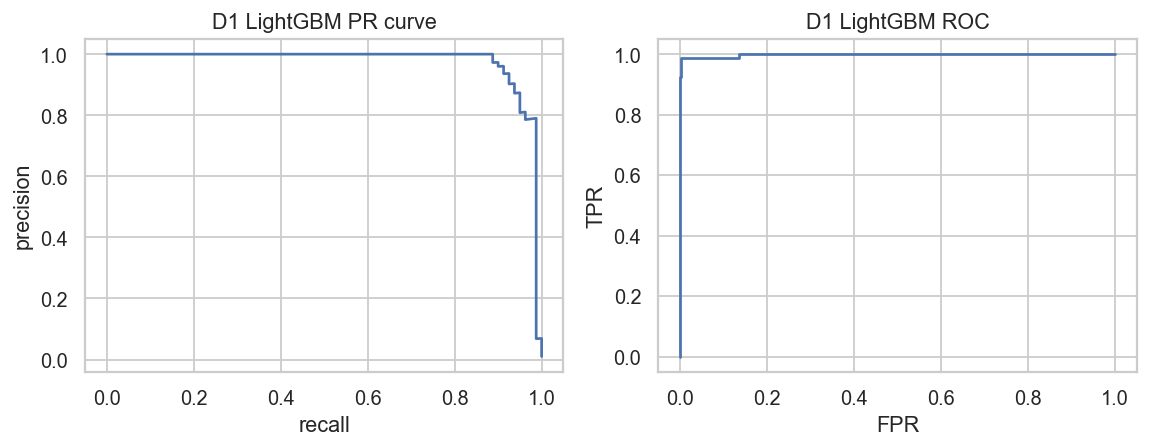

**D2**

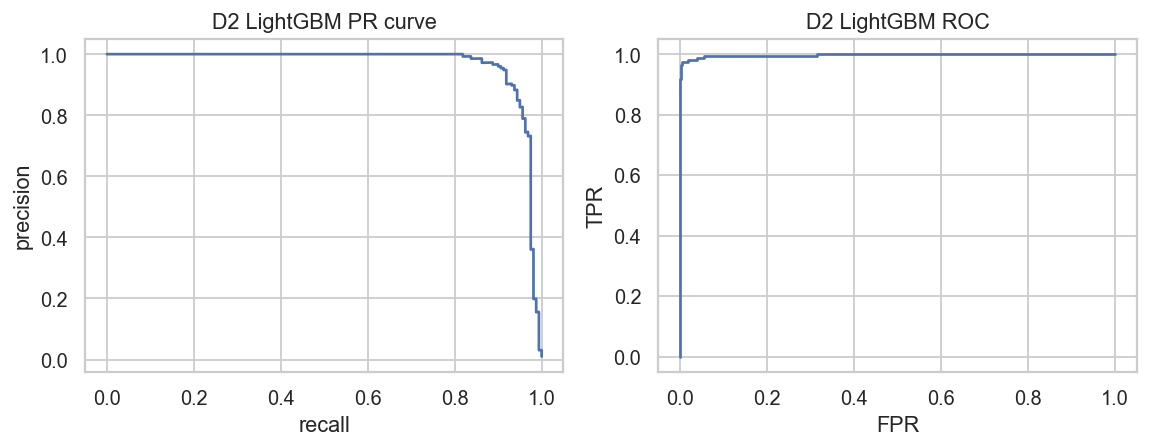

**D3**

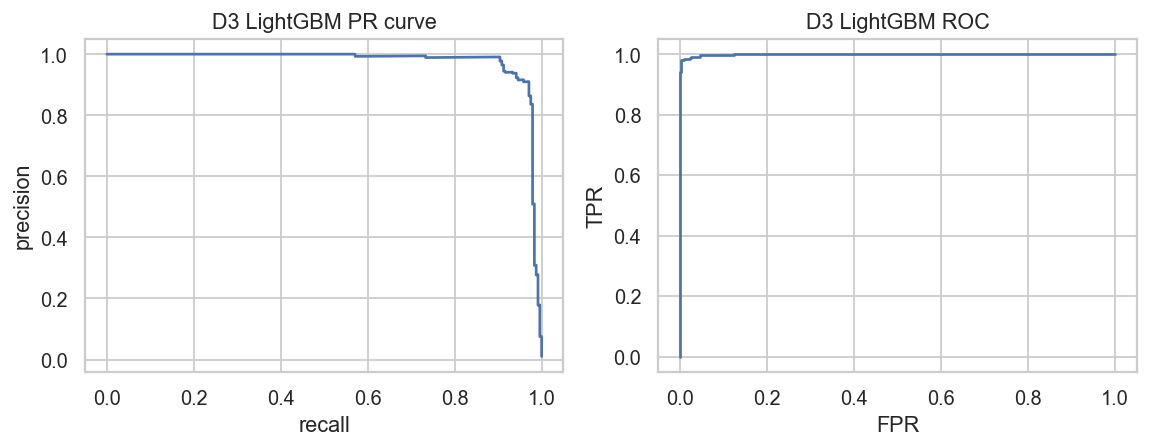

**D1 confusion (holdout)**

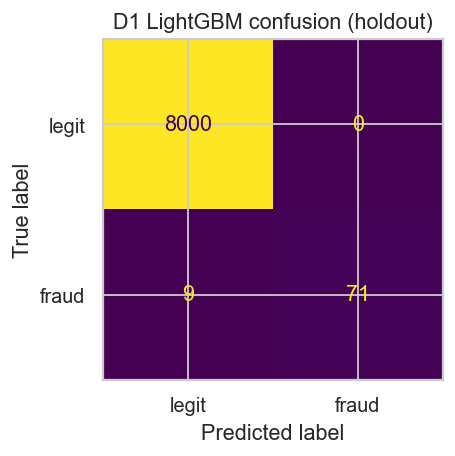

**D2**

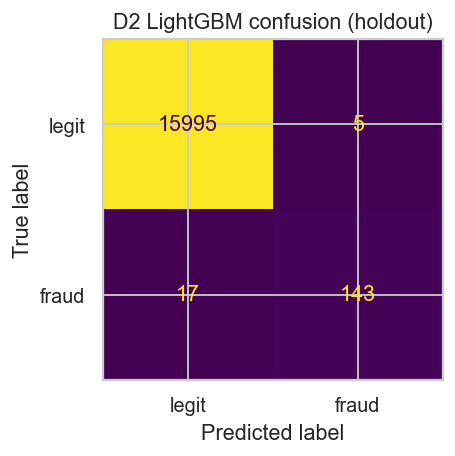

**D3**

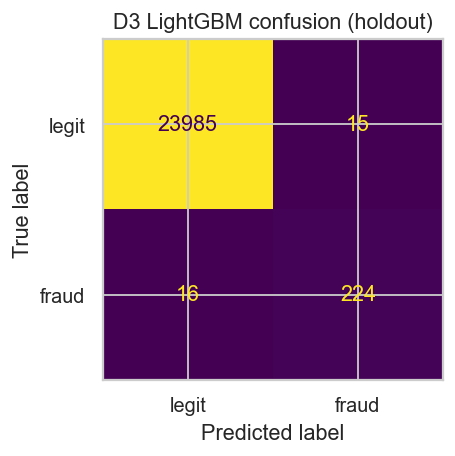

**V14 / V12 / V4 dominate, same as EDA**

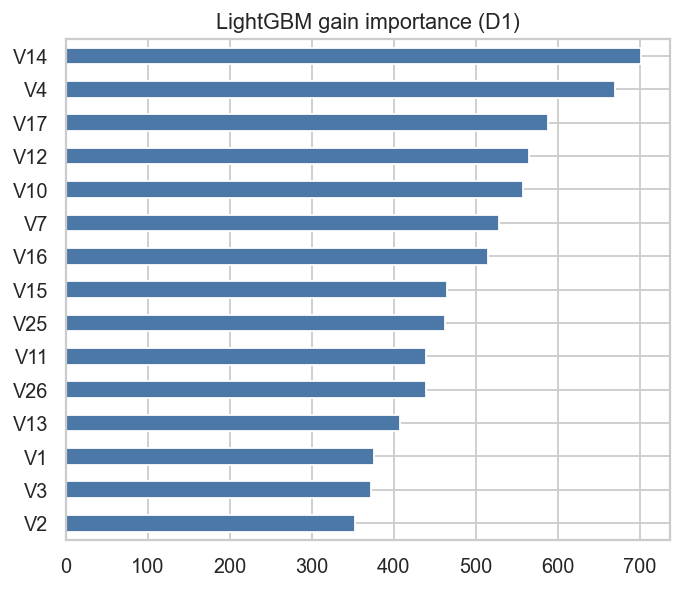

**Boosting is cheaper than the paper SVM on D3**

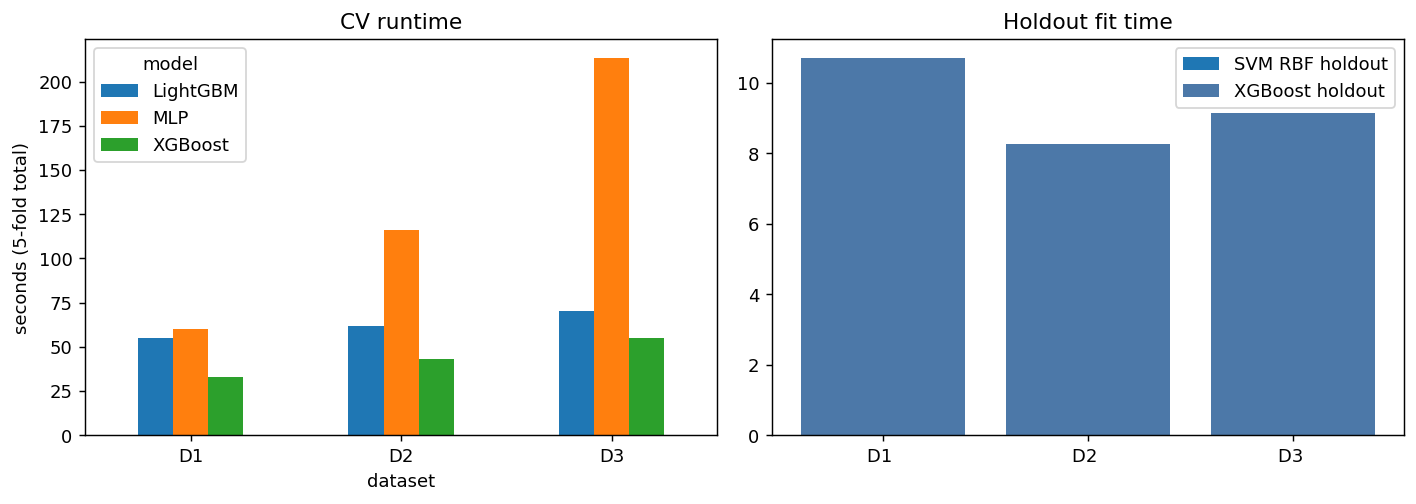

In [19]:
plot_dir = PLOTS_DIR / "compare"
for name, note in [
    ("d1_pr_roc.png", "D1 LightGBM PR / ROC"),
    ("d2_pr_roc.png", "D2"),
    ("d3_pr_roc.png", "D3"),
    ("d1_cm.png", "D1 confusion (holdout)"),
    ("d2_cm.png", "D2"),
    ("d3_cm.png", "D3"),
    ("lgb_importance_d1.png", "V14 / V12 / V4 dominate, same as EDA"),
    ("runtime.png", "Boosting is cheaper than the paper SVM on D3"),
]:
    p = plot_dir / name
    if p.exists():
        display(Markdown(f"**{note}**"))
        show_img(p)


## 7. Realistic 2013 data — skipped

PLAN said: only run on the ULB `creditcard.csv` (~0.17% fraud) if the file is present. It is not. I did not download it. Drop `data/creditcard.csv` in if you want this check later.


In [20]:
candidates = [ROOT / "data" / "creditcard.csv", ROOT / "creditcard.csv"]
print({str(p): p.exists() for p in candidates})
print("Step 7 skipped." if not any(p.exists() for p in candidates) else "File found.")


{'d:\\Acads\\Sem 5\\ML Lab\\Project\\Credit-card-fraud-detection-using-DBSCAN\\data\\creditcard.csv': False, 'd:\\Acads\\Sem 5\\ML Lab\\Project\\Credit-card-fraud-detection-using-DBSCAN\\creditcard.csv': False}
Step 7 skipped.


## Conclusion

- **Table 11 does not reproduce.** Our DVE recall is about 0.90–0.93, not 0.988–0.995. Paper-style and leakage-safe are close, so leakage is not the main story.
- **This 2023 Kaggle file is too easy.** It is balanced until we force 1% fraud. A logistic probe already has PR-AUC 0.95.
- **DBSCAN labels are a weak extra feature.** Most fraud is noise; most noise is still legit.
- **XGBoost / LightGBM with class weights beat the paper's 3-tree RF + OR-vote** without needing cluster labels.
- **Limits:** synthetic 1% sample, no drift, no 2013 file, sklearn MLP instead of PyTorch, CatBoost skipped on this CPU.

Do not copy 0.995 into a report as *our* number. Use the tables above.
